# Distribuciones y valores atípicos en ventas retail

**Objetivo.** Describir cómo se distribuyen los pedidos y detectar importes inusualmente altos o bajos mediante el rango intercuartílico (IQR).

Trabajamos con el archivo **ventas_retail.csv** provisto para la actividad, disponible en la Pre-Entrega 12. Cada fila del archivo analizado tiene un identificador de pedido distinto. Los importes se mantienen en las unidades monetarias del CSV.

## 1. Carga, limpieza y control de calidad

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
import pandas as pd
from IPython.display import display

ruta_datos = Path("data") / "ventas_retail.csv"
columnas_numericas = ["Ventas", "Precio_Unitario", "Unidades", "Costo"]
columnas_texto = ["ID_Pedido", "Categoria", "Producto", "Provincia", "Canal"]
columnas_requeridas = ["Fecha", *columnas_numericas, *columnas_texto]

datos_originales = pd.read_csv(ruta_datos, dtype={"ID_Pedido": "string"})
columnas_faltantes = set(columnas_requeridas) - set(datos_originales.columns)
if columnas_faltantes:
    raise ValueError(f"Faltan columnas en el CSV: {sorted(columnas_faltantes)}")

Matplotlib is building the font cache; this may take a moment.


In [2]:
datos_normalizados = datos_originales.copy()
datos_normalizados["Fecha"] = pd.to_datetime(
    datos_normalizados["Fecha"], format="%Y-%m-%d", errors="coerce"
)
for columna in columnas_texto:
    datos_normalizados[columna] = (
        datos_normalizados[columna].astype("string").str.strip().replace("", pd.NA)
    )
datos_normalizados[columnas_numericas] = (
    datos_normalizados[columnas_numericas]
    .apply(pd.to_numeric, errors="coerce")
    .replace([float("inf"), -float("inf")], float("nan"))
)

# Se conservan las filas observadas durante la limpieza para poder auditarlas.
sin_duplicados = datos_normalizados.drop_duplicates()
filas_incompletas = sin_duplicados[columnas_requeridas].isna().any(axis=1)
datos_excluidos = sin_duplicados.loc[filas_incompletas].copy()
ventas = sin_duplicados.loc[~filas_incompletas].copy()

# La coherencia del importe se controla por separado, sin excluir filas por el tamaño de la venta.
importe_calculado = (ventas["Precio_Unitario"] * ventas["Unidades"]).round(2)
inconsistencias_importe = ventas["Ventas"].round(2).ne(importe_calculado)
calidad = pd.Series(
    {
        "Filas originales": len(datos_originales),
        "Duplicados exactos descartados": len(datos_normalizados) - len(sin_duplicados),
        "Filas incompletas o inválidas excluidas": len(datos_excluidos),
        "Filas analizadas": len(ventas),
        "Pedidos únicos": ventas["ID_Pedido"].nunique(),
        "Ventas distintas de precio unitario × unidades": inconsistencias_importe.sum(),
    },
    name="Registros",
)
display(calidad.to_frame())
print(f"Período: {ventas['Fecha'].min():%Y-%m-%d} a {ventas['Fecha'].max():%Y-%m-%d}")

,Registros
Filas originales,2959
Duplicados exactos descartados,0
Filas incompletas o inválidas excluidas,0
Filas analizadas,2959
Pedidos únicos,2959
Ventas distintas de precio unitario × unidades,0


Período: 2025-10-01 a 2026-09-30


## 2. Frecuencias por categoría y canal
Las barras muestran conteos de registros de venta. Su altura o longitud no mide el importe vendido.

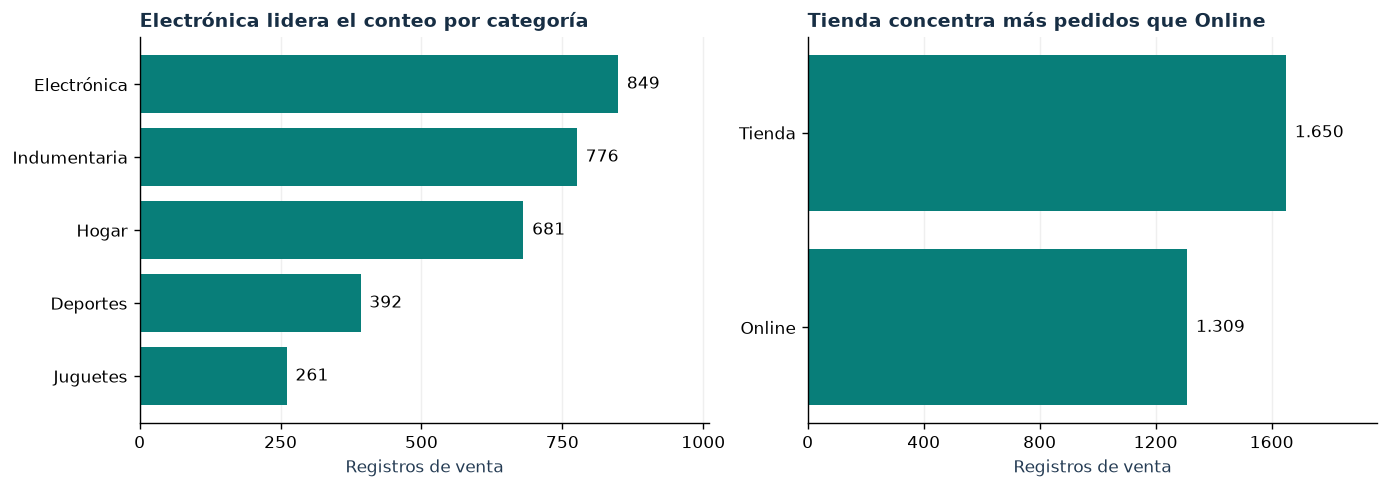

In [3]:
plt.rcParams.update({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.labelcolor": "#243B53",
    "axes.titlecolor": "#172E44",
    "figure.dpi": 125,
})

color_principal = "#087E79"
color_atipico = "#A64B12"


def formato_importe(valor, _):
    """Muestra importes grandes en miles o millones con coma decimal."""
    if abs(valor) >= 1_000_000:
        return f"{valor / 1_000_000:g}".replace(".", ",") + " M"
    return f"{valor / 1_000:g}".replace(".", ",") + " mil" if valor else "0"


fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
for eje, columna, titulo in zip(
    ejes,
    ["Categoria", "Canal"],
    ["Electrónica lidera el conteo por categoría", "Tienda concentra más pedidos que Online"],
):
    frecuencias = ventas[columna].value_counts().sort_values()
    barras = eje.barh(frecuencias.index, frecuencias.values, color=color_principal)
    eje.bar_label(barras, labels=[f"{n:,}".replace(",", ".") for n in frecuencias], padding=5)
    eje.set_xlim(0, frecuencias.max() * 1.19)
    eje.set_title(titulo, loc="left", fontsize=11)
    eje.set_xlabel("Registros de venta")
    eje.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
    eje.grid(axis="x", alpha=0.2)
    eje.set_axisbelow(True)

plt.show()

## 3. Tendencia central, dispersión y forma

La media resume el promedio y la mediana ubica el centro de la distribución. La desviación estándar muestral usa **ddof=1**. También se calculan mínimos, máximos y cuartiles.

Una **asimetría positiva** indica una cola hacia los valores altos. Una negativa indica una cola hacia los valores bajos. Usamos la **curtosis en exceso de Fisher**, cuya referencia normal es 0. Un exceso positivo señala colas con más peso relativo en el cuarto momento. Por sí solo, no clasifica registros ni prueba normalidad.

[Asimetría en Pandas](https://pandas.pydata.org/docs/reference/api/pandas.Series.skew.html) · [Curtosis en Pandas](https://pandas.pydata.org/docs/reference/api/pandas.Series.kurt.html)

In [4]:
numericos = ventas[columnas_numericas]
cuartiles = numericos.quantile([0.25, 0.75], interpolation="linear").T
cuartiles.columns = ["Q1", "Q3"]

resumen = pd.DataFrame({
    "Media": numericos.mean(),
    "Mediana": numericos.median(),
    "Desv. estándar": numericos.std(ddof=1),
    "Mínimo": numericos.min(),
    "Q1": cuartiles["Q1"],
    "Q3": cuartiles["Q3"],
    "IQR": cuartiles["Q3"] - cuartiles["Q1"],
    "Máximo": numericos.max(),
    "Asimetría": numericos.skew(),
    "Curtosis (exceso)": numericos.kurt(),
}).rename_axis("Variable")
display(resumen.round(3))

,Media,Mediana,Desv. estándar,Mínimo,Q1,Q3,IQR,Máximo,Asimetría,Curtosis (exceso)
Variable,,,,,,,,,,
Ventas,197420.919,121000.0,208460.773,4500,61000.0,257000.0,196000.0,1260000,2.185,5.610
Precio_Unitario,117679.790,80500.0,101800.765,4000,44000.0,155250.0,111250.0,420000,1.301,0.804
Unidades,1.672,2.0,0.749,1,1.0,2.0,1.0,3,0.618,-0.982
Costo,138980.484,76156.0,162706.515,2662,36518.0,174577.5,138059.5,1003600,2.330,6.259


En **Ventas**, la media es **197.420,92** y supera la mediana de **121.000**. Esto coincide con la asimetría de **2,185** y con una cola que llega a **1.260.000**. La curtosis en exceso es **5,610**. Para describir un pedido típico, la mediana es más representativa porque responde menos a los importes altos.

## 4. Segmentación por rango intercuartílico

El IQR es la diferencia entre el percentil 75 (**Q3**) y el percentil 25 (**Q1**). Los límites se calculan con **Q1 − 1,5 × IQR** y **Q3 + 1,5 × IQR**. Un valor se etiqueta como **Atípico inferior** si es estrictamente menor que el límite bajo y como **Atípico superior** si supera el límite alto. Los valores iguales a los límites quedan dentro del rango.

Aplicamos la regla al total del archivo. Para **Ventas** también calculamos límites por categoría, porque una compra de Electrónica puede tener un importe habitual distinto del de Juguetes.

In [5]:
def calcular_limites(q1, q3):
    """Devuelve el IQR y los límites inferior y superior de Tukey."""
    iqr = q3 - q1
    return iqr, q1 - 1.5 * iqr, q3 + 1.5 * iqr


def segmentar_iqr(importes, limite_inferior, limite_superior):
    """Clasifica cada importe con límites escalares o alineados por fila."""
    segmento = pd.Series("Dentro del rango IQR", index=importes.index, dtype="string")
    segmento.loc[importes.lt(limite_inferior)] = "Atípico inferior"
    segmento.loc[importes.gt(limite_superior)] = "Atípico superior"
    return segmento


limites = cuartiles.copy()
limites["IQR"], limites["Límite inferior"], limites["Límite superior"] = calcular_limites(
    limites["Q1"], limites["Q3"]
)
limites["Atípicos inferiores"] = numericos.lt(limites["Límite inferior"]).sum()
limites["Atípicos superiores"] = numericos.gt(limites["Límite superior"]).sum()
display(limites.rename_axis("Variable").round(2))

limite_ventas = limites.loc["Ventas"]
ventas["Segmento_IQR_global"] = segmentar_iqr(
    ventas["Ventas"], limite_ventas["Límite inferior"], limite_ventas["Límite superior"]
)

# Cada categoría recibe sus propios límites y estos se asignan por nombre de categoría.
cuartiles_categoria = (
    ventas.groupby("Categoria")["Ventas"].quantile([0.25, 0.75], interpolation="linear").unstack()
)
limites_categoria = cuartiles_categoria.rename(columns={0.25: "Q1", 0.75: "Q3"})
(
    limites_categoria["IQR"],
    limites_categoria["Límite inferior"],
    limites_categoria["Límite superior"],
) = calcular_limites(limites_categoria["Q1"], limites_categoria["Q3"])
ventas["Limite_IQR_categoria_superior"] = ventas["Categoria"].map(limites_categoria["Límite superior"])
ventas["Limite_IQR_categoria_inferior"] = ventas["Categoria"].map(limites_categoria["Límite inferior"])
ventas["Segmento_IQR_categoria"] = segmentar_iqr(
    ventas["Ventas"], ventas["Limite_IQR_categoria_inferior"], ventas["Limite_IQR_categoria_superior"]
)

,Q1,Q3,IQR,Límite inferior,Límite superior,Atípicos inferiores,Atípicos superiores
Variable,,,,,,,
Ventas,61000.0,257000.0,196000.0,-233000.00,551000.00,0,205
Precio_Unitario,44000.0,155250.0,111250.0,-122875.00,322125.00,0,218
Unidades,1.0,2.0,1.0,-0.50,3.50,0,0
Costo,36518.0,174577.5,138059.5,-170571.25,381666.75,0,234


## 5. Boxplot de ventas y violines por categoría

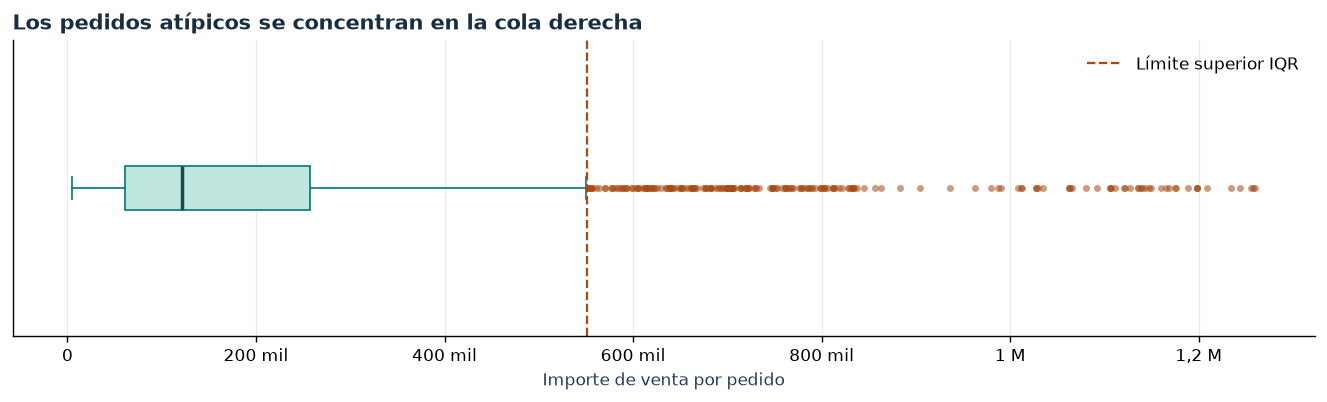

In [6]:
fig, eje = plt.subplots(figsize=(10.5, 3.1), layout="constrained")
eje.boxplot(
    ventas["Ventas"], orientation="horizontal", whis=1.5, showfliers=True, patch_artist=True,
    boxprops={"facecolor": "#BFE6DF", "edgecolor": color_principal},
    medianprops={"color": "#174D4C", "linewidth": 2},
    whiskerprops={"color": color_principal},
    capprops={"color": color_principal},
    flierprops={"marker": "o", "markerfacecolor": color_atipico, "markeredgecolor": "none",
                "markersize": 4, "alpha": 0.55},
)
eje.axvline(
    limite_ventas["Límite superior"], color=color_atipico, linestyle="--", linewidth=1.3,
    label="Límite superior IQR",
)
eje.set_title("Los pedidos atípicos se concentran en la cola derecha", loc="left")
eje.set_xlabel("Importe de venta por pedido")
eje.set_yticks([])
eje.xaxis.set_major_formatter(FuncFormatter(formato_importe))
eje.grid(axis="x", alpha=0.23)
eje.legend(loc="upper right", frameon=False)
plt.show()

La caja abarca de Q1 a Q3 y la línea interna marca la mediana. Los bigotes llegan a las observaciones más alejadas que siguen dentro de los límites. Los puntos naranjas son observaciones fuera de esos límites. El límite inferior queda fuera de la escala mostrada porque es negativo y todos los importes observados son positivos.

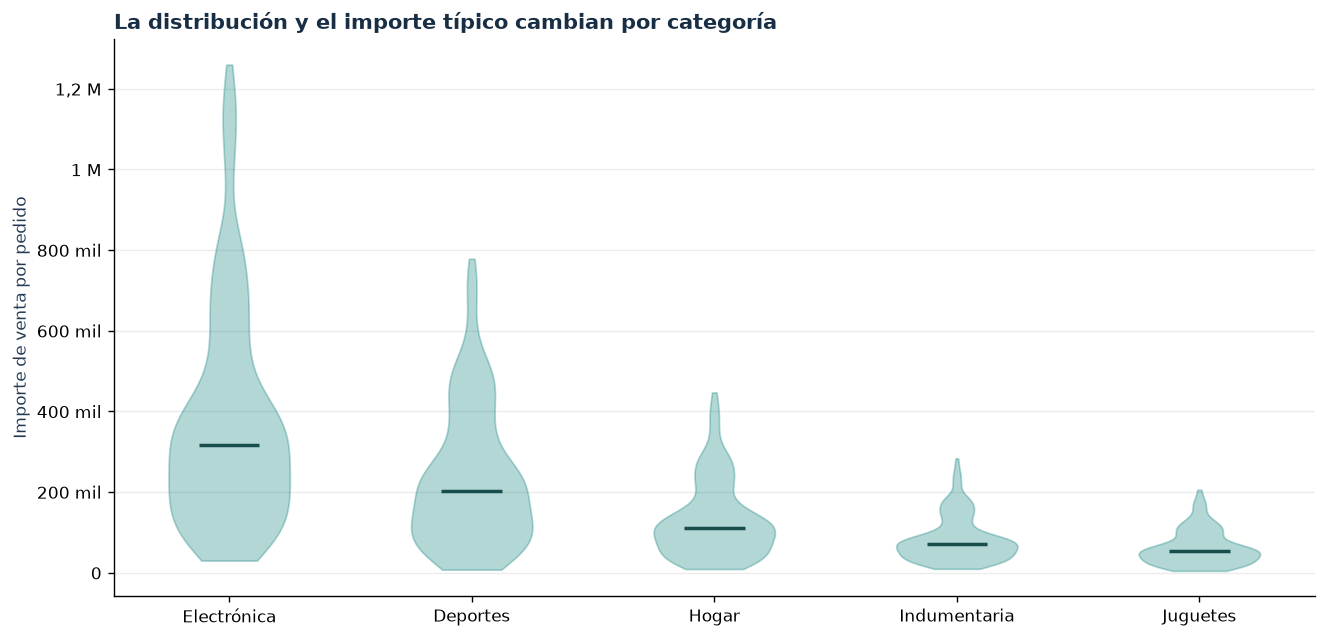

In [7]:
medianas_categoria = ventas.groupby("Categoria")["Ventas"].median().sort_values(ascending=False)
orden_categorias = medianas_categoria.index.tolist()
importes_por_categoria = [
    ventas.loc[ventas["Categoria"].eq(categoria), "Ventas"].to_numpy()
    for categoria in orden_categorias
]
posiciones = range(1, len(orden_categorias) + 1)

fig, eje = plt.subplots(figsize=(10.5, 5), layout="constrained")
violines = eje.violinplot(
    importes_por_categoria, positions=list(posiciones), showmedians=True, showextrema=False
)
for cuerpo in violines["bodies"]:
    cuerpo.set_facecolor(color_principal)
    cuerpo.set_edgecolor(color_principal)
    cuerpo.set_alpha(0.31)
violines["cmedians"].set_color("#174D4C")
violines["cmedians"].set_linewidth(2)

eje.set_xticks(list(posiciones), orden_categorias)
eje.set_title("La distribución y el importe típico cambian por categoría", loc="left")
eje.set_ylabel("Importe de venta por pedido")
eje.yaxis.set_major_formatter(FuncFormatter(formato_importe))
eje.grid(axis="y", alpha=0.23)
eje.set_axisbelow(True)
plt.show()

La anchura del violín representa la densidad estimada de importes y la marca interna muestra la mediana de cada categoría. Electrónica tiene la mediana más alta (**317.500**) y el rango de importes más amplio. El IQR por categoría permite separar casos poco habituales dentro de cada línea de producto. [Boxplots y violines en Matplotlib](https://matplotlib.org/stable/gallery/statistics/boxplot_vs_violin.html)

## 6. Registros atípicos y decisión de tratamiento

In [8]:
segmentos = ["Atípico inferior", "Dentro del rango IQR", "Atípico superior"]
conteos = pd.DataFrame({
    "IQR global": ventas["Segmento_IQR_global"].value_counts(),
    "IQR por categoría": ventas["Segmento_IQR_categoria"].value_counts(),
}).reindex(segmentos).fillna(0).astype(int)
display(conteos)

# Conservar los dos indicadores permite comparar los criterios sin eliminar observaciones.
detalle = ventas.assign(
    Marcado_global=ventas["Segmento_IQR_global"].ne("Dentro del rango IQR"),
    Marcado_por_categoria=ventas["Segmento_IQR_categoria"].ne("Dentro del rango IQR"),
)
resumen_por_categoria = detalle.groupby("Categoria").agg(
    Pedidos=("ID_Pedido", "size"),
    Atipicos_globales=("Marcado_global", "sum"),
    Atipicos_por_categoria=("Marcado_por_categoria", "sum"),
).join(limites_categoria[["Límite superior"]])
display(resumen_por_categoria.sort_values("Atipicos_globales", ascending=False))

outliers_ventas = detalle.loc[detalle["Marcado_global"]].sort_values("Ventas", ascending=False).copy()
display(pd.crosstab(outliers_ventas["Categoria"], outliers_ventas["Canal"]))

columnas_revision = [
    "ID_Pedido", "Fecha", "Categoria", "Producto", "Provincia", "Canal", "Unidades",
    "Precio_Unitario", "Ventas", "Segmento_IQR_global", "Segmento_IQR_categoria",
    "Limite_IQR_categoria_inferior", "Limite_IQR_categoria_superior",
]
display(outliers_ventas[columnas_revision].head(12))

ruta_resultados = Path("resultados") / "outliers_ventas_iqr.csv"
ruta_resultados.parent.mkdir(exist_ok=True)
outliers_ventas[columnas_revision].to_csv(ruta_resultados, index=False)
print(f"{len(outliers_ventas)} registros guardados en {ruta_resultados}.")
print(f"Proporción de pedidos marcados: {len(outliers_ventas) / len(ventas):.2%}")
print(f"Participación en las ventas: {outliers_ventas['Ventas'].sum() / ventas['Ventas'].sum():.2%}")

,IQR global,IQR por categoría
Atípico inferior,0,0
Dentro del rango IQR,2754,2849
Atípico superior,205,110


,Pedidos,Atipicos_globales,Atipicos_por_categoria,Límite superior
Categoria,,,,
Electrónica,849,185,44,981250.0
Deportes,392,20,9,694375.0
Hogar,681,0,22,357500.0
Indumentaria,776,0,32,201750.0
Juguetes,261,0,3,185000.0


Canal,Online,Tienda
Categoria,,
Deportes,9,11
Electrónica,98,87


,ID_Pedido,Fecha,Categoria,Producto,Provincia,Canal,Unidades,Precio_Unitario,Ventas,Segmento_IQR_global,Segmento_IQR_categoria,Limite_IQR_categoria_inferior,Limite_IQR_categoria_superior
1354,P001355,2026-03-20,Electrónica,Parlante Bluetooth,Córdoba,Tienda,3,420000,1260000,Atípico superior,Atípico superior,-304750.0,981250.0
510,P000511,2025-12-02,Electrónica,Smart TV,Buenos Aires,Tienda,3,419000,1257000,Atípico superior,Atípico superior,-304750.0,981250.0
1076,P001077,2026-02-08,Electrónica,Tablet,Neuquén,Tienda,3,418500,1255500,Atípico superior,Atípico superior,-304750.0,981250.0
410,P000411,2025-11-21,Electrónica,Smartwatch,Tucumán,Online,3,414500,1243500,Atípico superior,Atípico superior,-304750.0,981250.0
1013,P001014,2026-01-29,Electrónica,Smartwatch,Entre Ríos,Tienda,3,411500,1234500,Atípico superior,Atípico superior,-304750.0,981250.0
2101,P002102,2026-06-23,Electrónica,Auriculares,Buenos Aires,Tienda,3,403000,1209000,Atípico superior,Atípico superior,-304750.0,981250.0
126,P000127,2025-10-19,Electrónica,Parlante Bluetooth,Tucumán,Online,3,399500,1198500,Atípico superior,Atípico superior,-304750.0,981250.0
1092,P001093,2026-02-10,Electrónica,Tablet,Entre Ríos,Tienda,3,399500,1198500,Atípico superior,Atípico superior,-304750.0,981250.0
688,P000689,2025-12-19,Electrónica,Smart TV,Entre Ríos,Online,3,399500,1198500,Atípico superior,Atípico superior,-304750.0,981250.0
810,P000811,2026-01-01,Electrónica,Smartwatch,Santa Fe,Online,3,396000,1188000,Atípico superior,Atípico superior,-304750.0,981250.0


205 registros guardados en resultados/outliers_ventas_iqr.csv.
Proporción de pedidos marcados: 6.93%
Participación en las ventas: 27.80%


### Qué haría con los outliers

El límite superior global es **551.000**. Se marcan **205 pedidos** (**6,93 %** del total), todos por encima del límite. **185** pertenecen a Electrónica y **20** a Deportes. Al comparar cada pedido con su propia categoría, se marcan **110** en total, incluidos **44** en Electrónica. Las dos reglas responden preguntas distintas y pueden señalar pedidos diferentes.

Mantendría los pedidos en el análisis de ventas. En conjunto representan **27,80 %** del importe y el control **Ventas = Precio_Unitario × Unidades** coincide en todos los registros. Revisaría primero los pedidos más altos con los comprobantes o el catálogo y corregiría los errores que se puedan confirmar. Para modelar importes, evaluaría **log1p** o una pérdida robusta. Si el IQR se usa en el preprocesamiento del modelo, calcularía sus límites con el conjunto de entrenamiento y aplicaría esos mismos límites a validación y prueba.